In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import v2
from torchvision import datasets, transforms
import torch.optim as optim
import matplotlib.pyplot as plt
import numpy as np
import torch.nn.functional as F

In [2]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

Using mps device


### Loading the Dataset

__1. Convert images to tensor + flatten__

__2. Load the data + Split__

__3. Create a data loader to fetch data in batches for training__

In [3]:
# =========================
# Dataset
# =========================

#========================= 1 ========================= 
transform = transforms.Compose([
    transforms.ToTensor(),                  # image -> tensor [0,1]
    transforms.Lambda(lambda x: x.view(-1)) # flatten 28x28 -> 784
])

#========================= 2 ========================= 
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    transform=transform,
    download=True
)

### train = False (pas le train ni validation dataset)
test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    transform=transform,
    download=True
)

### Split
train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size
train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

#========================= 3 ========================= 
### Le DataLoader retourne ici deux choses : (les images, les labels), mais osef des labels
train_loader = DataLoader(train_dataset, batch_size=256, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False)

In [4]:
# =========================
# Fixed noisy test set
# =========================
noise_factor = 0.5

### Tout le test set (10 000 images) dans un seul tensor
x_test_all = torch.stack([test_dataset[i][0] for i in range(len(test_dataset))])

### Meme bruit pour tous les modeles (seed fixe)
g = torch.Generator().manual_seed(42)
noise_test = noise_factor * torch.randn(x_test_all.shape, generator=g)
x_test_noisy_all = torch.clamp(x_test_all + noise_test, 0., 1.)


# =========================
# MSE on the FULL test set
# =========================
def mse_full_test_set(model, x_input, x_target, batch_size=256):
    model.eval()
    mse_per_image = []
    with torch.no_grad():
        for i in range(0, len(x_input), batch_size):
            xb_in = x_input[i:i + batch_size].to(device)
            xb_target = x_target[i:i + batch_size].to(device)
            x_hat = model(xb_in)
            ### MSE par image (moyenne sur les 784 pixels)
            mse_per_image.append(((x_hat - xb_target) ** 2).mean(dim=1).cpu())
    return torch.cat(mse_per_image).mean().item()


# =========================
# Show 5 images + their MSE
# =========================
def show_reconstructions(model, x_input, x_target, n=5, title=""):
    model.eval()
    with torch.no_grad():
        x_hat = model(x_input[:n].to(device)).cpu()

    plt.figure(figsize=(n * 2, 6))
    for i in range(n):
        mse = torch.mean((x_target[i] - x_hat[i]) ** 2).item()
        print(f"Image {i+1}: MSE = {mse:.5f}")

        plt.subplot(3, n, i + 1)
        plt.imshow(x_target[i].reshape(28, 28), cmap="gray")
        plt.title("Original")
        plt.axis("off")

        plt.subplot(3, n, i + 1 + n)
        plt.imshow(x_input[i].reshape(28, 28), cmap="gray")
        plt.title("Input")
        plt.axis("off")

        plt.subplot(3, n, i + 1 + 2 * n)
        plt.imshow(x_hat[i].reshape(28, 28), cmap="gray")
        plt.title(f"MSE={mse:.4f}")
        plt.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

### Define the AE

In [5]:
# Autoencoder model
class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder: 784 -> 512 -> 256
        self.encoder = nn.Sequential(
            nn.Linear(784, 512),
            nn.ReLU(),
            nn.Linear(512, 256),
            nn.ReLU()
        )

        # Decoder: 256 -> 512 -> 784
        self.decoder = nn.Sequential(
            nn.Linear(256, 512),
            nn.ReLU(),
            nn.Linear(512, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return x_hat


### Initializing Model

In [6]:
model = Autoencoder().to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

### Traning the model

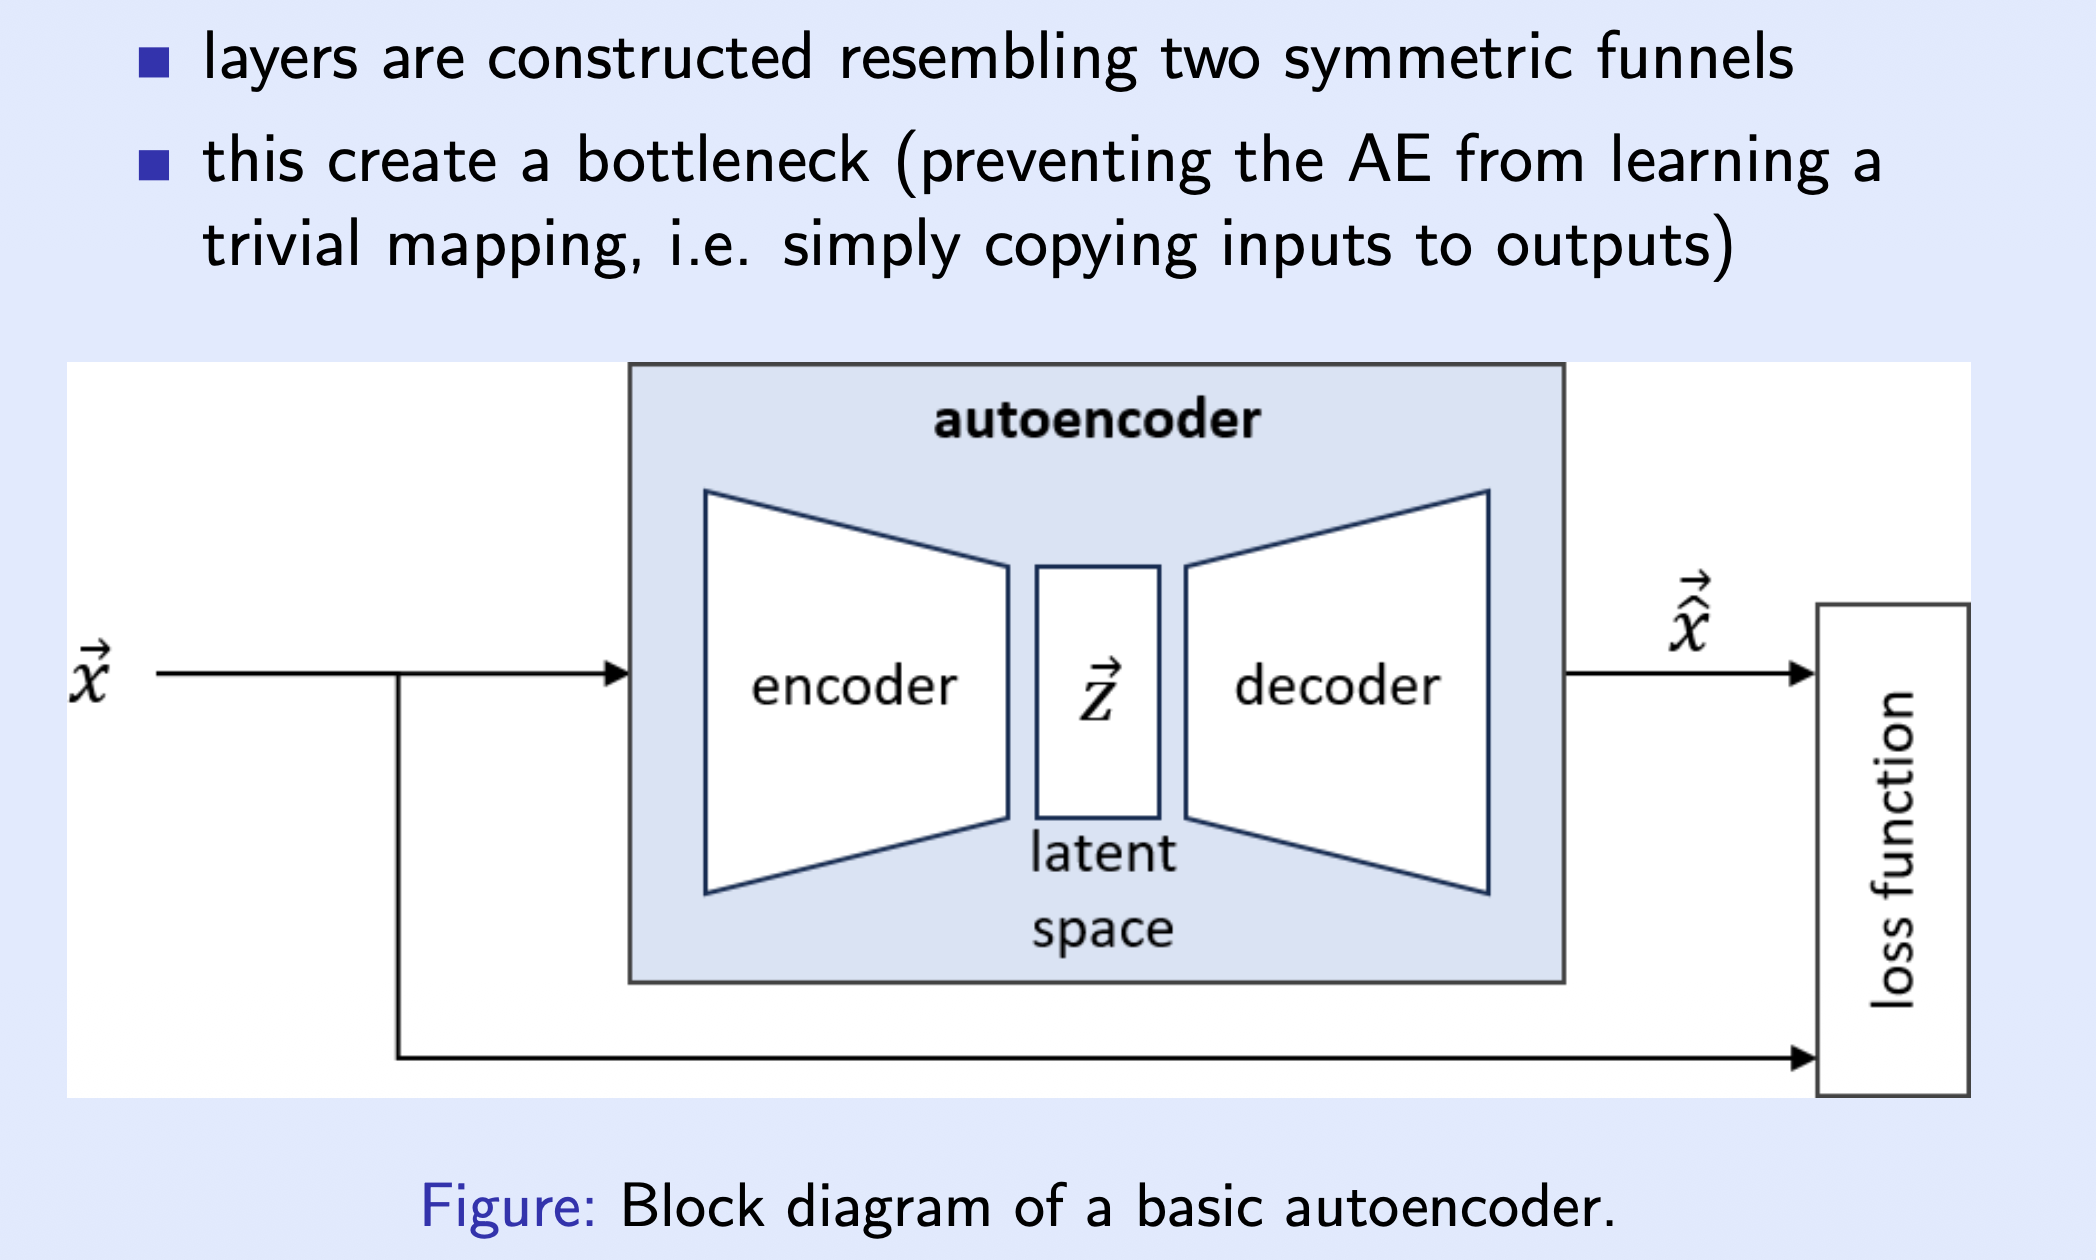

In [7]:
# =========================
# Training Loop
# =========================
train_losses = []
val_losses = []
n_epochs = 50

for epoch in range(1, n_epochs + 1):
    model.train()
    train_loss = 0.0

    # x : les images, _ : les labels (osef)
    for x, _ in train_loader:
        x = x.to(device)

        x_hat = model(x)
        loss = criterion(x_hat, x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        ### les batch ont le meme nombre d'images sauf peut etre le dernier
        ### exemple un batch de 256 avec un loss de = ..., et un batch de 128 images avec un loss de ....
        ### Pour que se soit equitable :  moyenne des loss × nombre d'images
        train_loss += loss.item() * x.size(0)   ## x.size(0) recupere la taille du batch

    epoch_train_loss = train_loss / train_size

    model.eval()
    val_loss = 0.0
    
    ## torch no_grad() signifie : ne calcule pas les gradient
    ## On veut mesurer la performance (validation set), pas apprendre
    with torch.no_grad():
        for x, _ in val_loader:
            x = x.to(device)

            x_hat = model(x)
            loss = criterion(x_hat, x)

            val_loss += loss.item() * x.size(0)

    epoch_val_loss = val_loss / val_size

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch {epoch:02d}/{n_epochs} | "
        f"Train Loss: {epoch_train_loss:.5f} | "
        f"Val Loss: {epoch_val_loss:.5f}"
    )

Epoch 01/50 | Train Loss: 0.05631 | Val Loss: 0.02712
Epoch 02/50 | Train Loss: 0.02014 | Val Loss: 0.01580
Epoch 03/50 | Train Loss: 0.01372 | Val Loss: 0.01213
Epoch 04/50 | Train Loss: 0.01084 | Val Loss: 0.01031
Epoch 05/50 | Train Loss: 0.00902 | Val Loss: 0.00849
Epoch 06/50 | Train Loss: 0.00788 | Val Loss: 0.00754
Epoch 07/50 | Train Loss: 0.00692 | Val Loss: 0.00718
Epoch 08/50 | Train Loss: 0.00622 | Val Loss: 0.00603
Epoch 09/50 | Train Loss: 0.00563 | Val Loss: 0.00555
Epoch 10/50 | Train Loss: 0.00523 | Val Loss: 0.00525
Epoch 11/50 | Train Loss: 0.00483 | Val Loss: 0.00481
Epoch 12/50 | Train Loss: 0.00451 | Val Loss: 0.00461
Epoch 13/50 | Train Loss: 0.00427 | Val Loss: 0.00429
Epoch 14/50 | Train Loss: 0.00404 | Val Loss: 0.00407
Epoch 15/50 | Train Loss: 0.00382 | Val Loss: 0.00397
Epoch 16/50 | Train Loss: 0.00367 | Val Loss: 0.00379
Epoch 17/50 | Train Loss: 0.00350 | Val Loss: 0.00357
Epoch 18/50 | Train Loss: 0.00335 | Val Loss: 0.00346
Epoch 19/50 | Train Loss: 0.

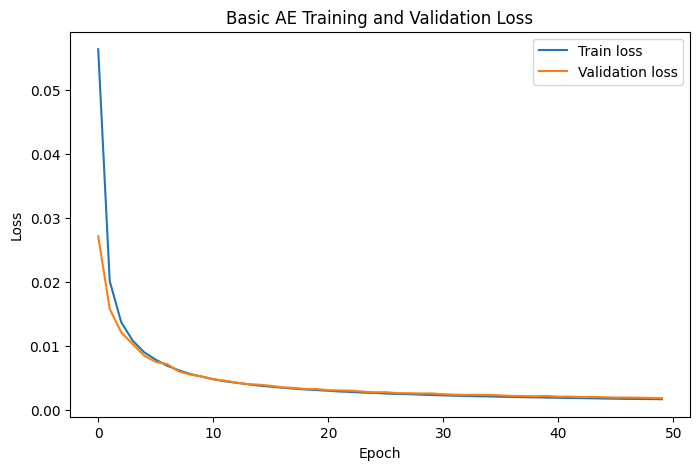

In [8]:
# =========================
# Plot Train / Validation Loss
# =========================
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Basic AE Training and Validation Loss")
plt.legend()
plt.show()

### Show reconstruction erros and reconstructions for selected images: (With test dataset)

Image 1: MSE = 0.00099
Image 2: MSE = 0.00281
Image 3: MSE = 0.00039
Image 4: MSE = 0.00158
Image 5: MSE = 0.00176


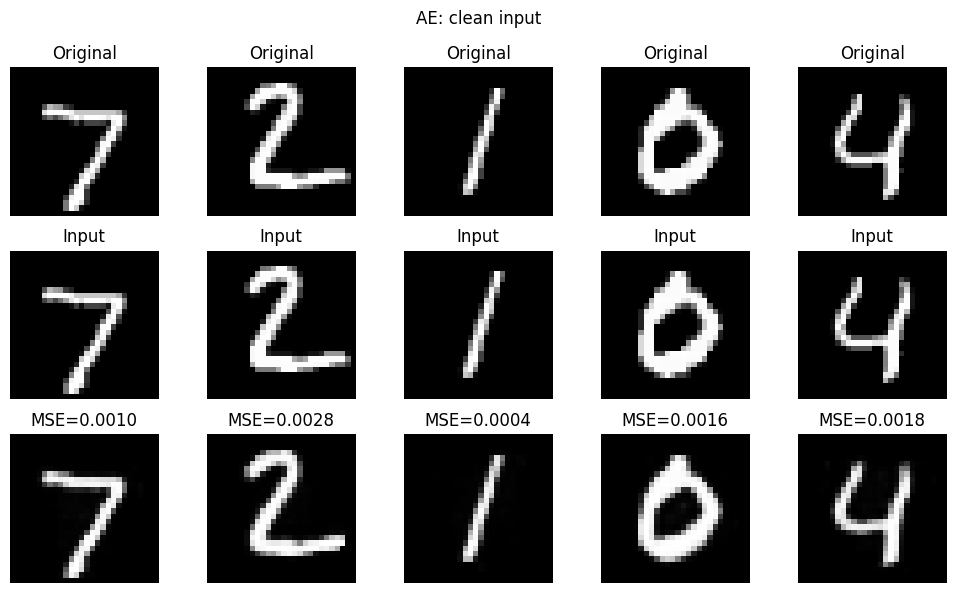


AE, clean input: mean MSE on all 10,000 test images = 0.00181


In [9]:
ae_model = model   # on garde l'AE de cote, car "model" sera ecrase par le DAE

show_reconstructions(ae_model, x_test_all, x_test_all, title="AE: clean input")

ae_clean_mse = mse_full_test_set(ae_model, x_test_all, x_test_all)
print(f"\nAE, clean input: mean MSE on all 10,000 test images = {ae_clean_mse:.5f}")


### Adding Gaussian Noise : 

Image 1: MSE = 0.04319
Image 2: MSE = 0.05848
Image 3: MSE = 0.03083
Image 4: MSE = 0.04350
Image 5: MSE = 0.02673


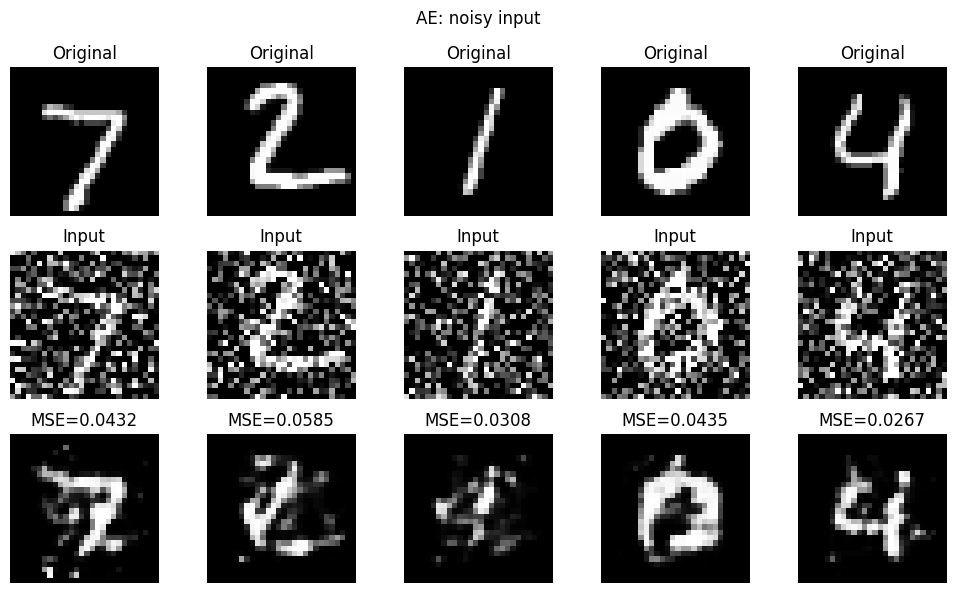


AE, noisy input: mean MSE on all 10,000 test images = 0.04662


In [10]:
show_reconstructions(ae_model, x_test_noisy_all, x_test_all, title="AE: noisy input")

ae_noisy_mse = mse_full_test_set(ae_model, x_test_noisy_all, x_test_all)
print(f"\nAE, noisy input: mean MSE on all 10,000 test images = {ae_noisy_mse:.5f}")

## Traning with perturbations : 

In [11]:
model = Autoencoder().to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

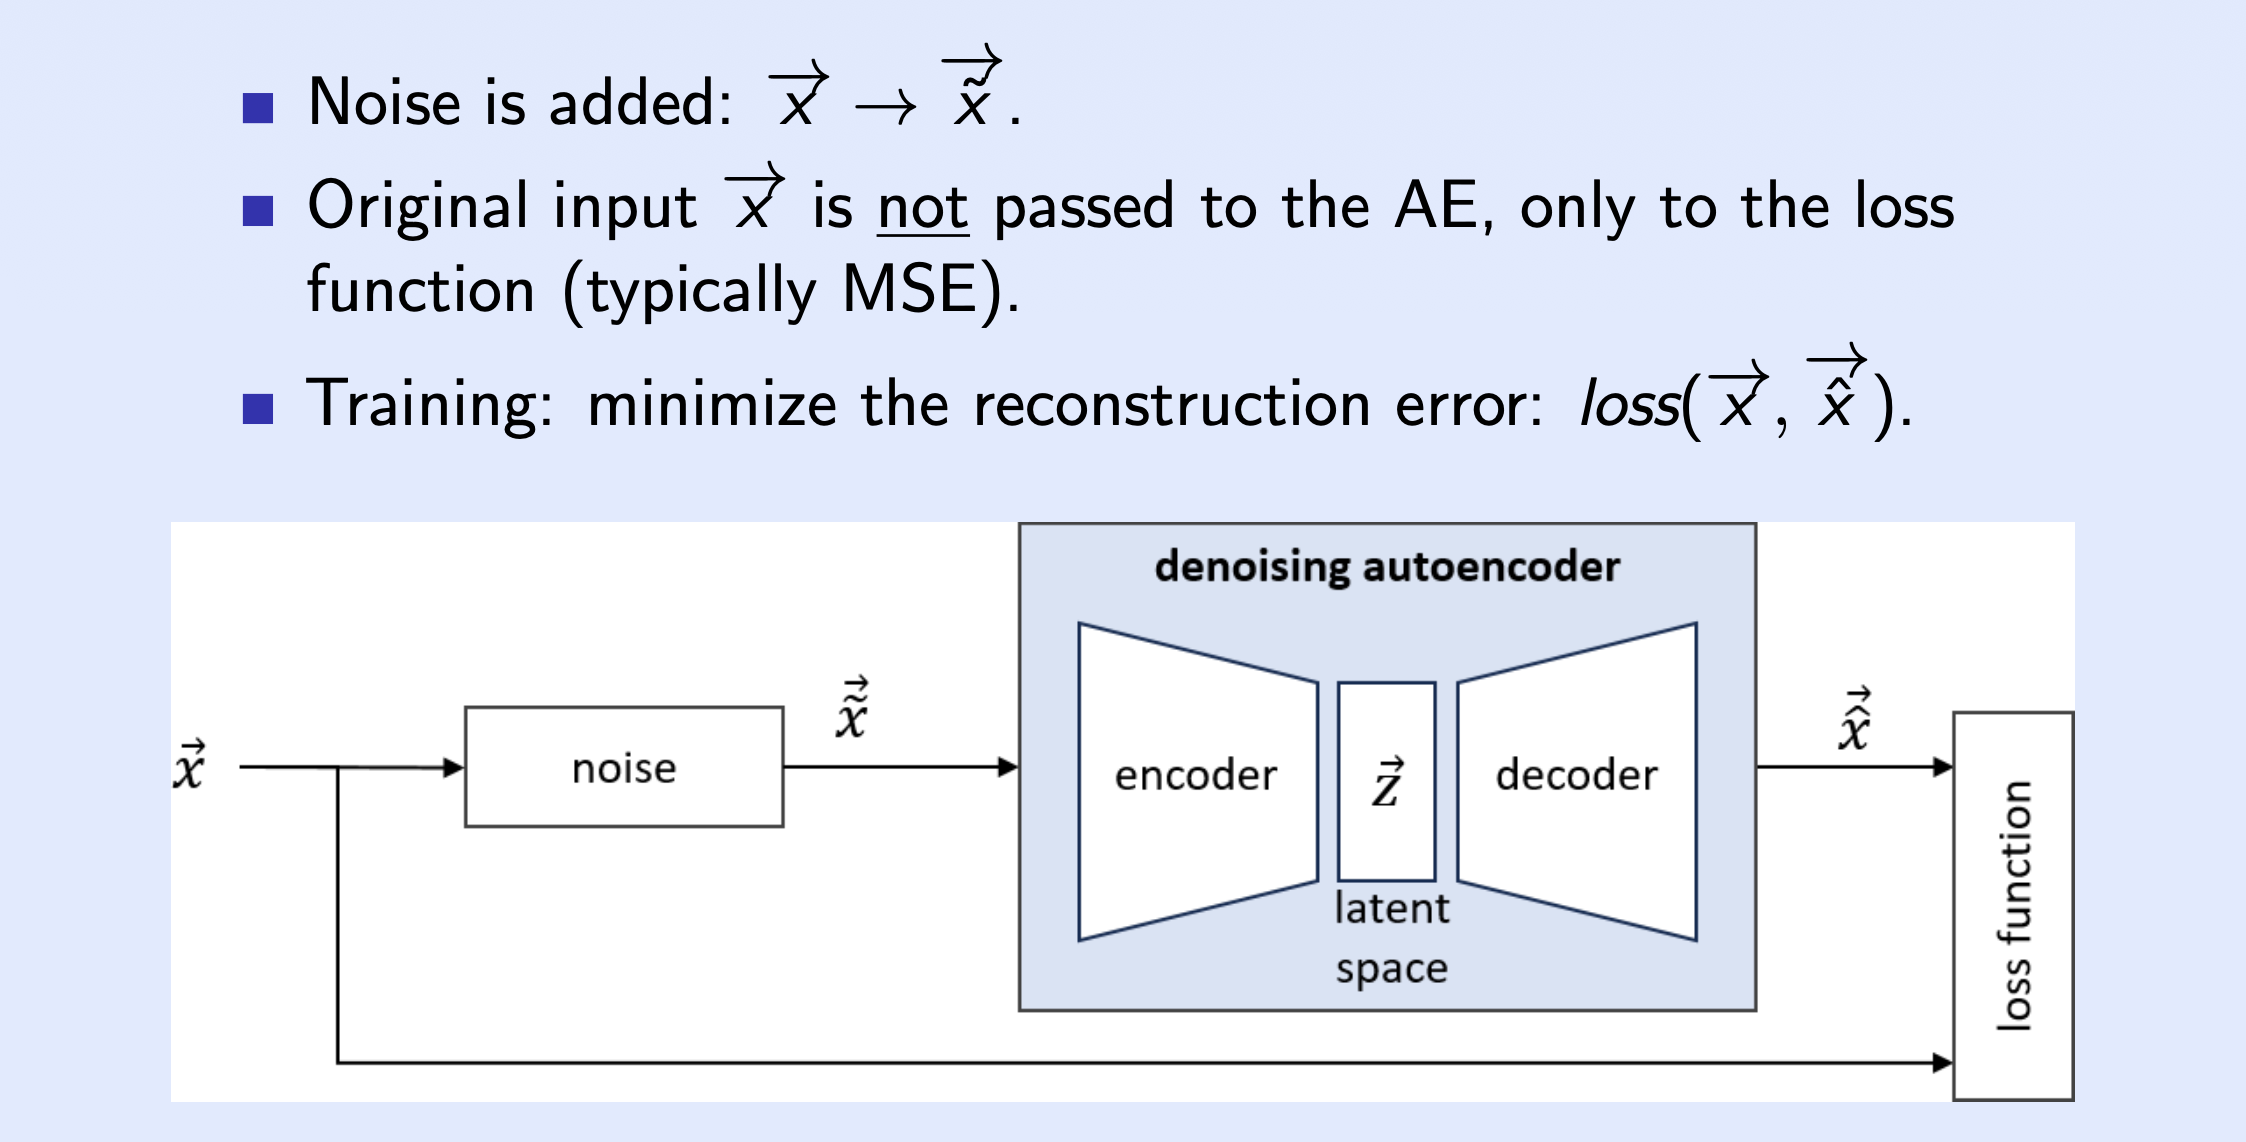

In [12]:
# =========================
# Training Loop
# =========================
train_losses = []
val_losses = []
n_epochs = 50

for epoch in range(1, n_epochs + 1):
    model.train()
    train_loss = 0.0

    # x : les images, _ : les labels (osef)
    for x, _ in train_loader:
        x = x.to(device)
    
        ## adding noise
        noise = 0.5 * torch.randn_like(x)
        x_noisy = torch.clamp(x + noise,0,1)
        
        ## Input : x_noisy, Target : x
        ## x_noisy -> Encoder -> Decoder -> x_hat
        ## le loss(x, x_hat)
        x_hat = model(x_noisy)
        loss = criterion(x_hat, x)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        ### les batch ont le meme nombre d'images sauf peut etre le dernier
        ### exemple un batch de 256 avec un loss de = ..., et un batch de 128 images avec un loss de ....
        ### Pour que se soit equitable :  moyenne des loss × nombre d'images
        train_loss += loss.item() * x.size(0)   ## x.size(0) recupere la taille du batch

    epoch_train_loss = train_loss / train_size

    model.eval()
    val_loss = 0.0
    
    ## torch no_grad() signifie : ne calcule pas les gradient
    ## On veut mesurer la performance (validation set), pas apprendre
    with torch.no_grad():
        for x, _ in val_loader:
            x = x.to(device)

            noise = noise_factor * torch.randn_like(x)
            x_noisy = torch.clamp(x + noise, 0, 1)
            x_hat = model(x_noisy)
            loss = criterion(x_hat, x)

            val_loss += loss.item() * x.size(0)
    epoch_val_loss = val_loss / val_size

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch {epoch:02d}/{n_epochs} | "
        f"Train Loss: {epoch_train_loss:.5f} | "
        f"Val Loss: {epoch_val_loss:.5f}"
    )

Epoch 01/50 | Train Loss: 0.06370 | Val Loss: 0.04076
Epoch 02/50 | Train Loss: 0.03393 | Val Loss: 0.02966
Epoch 03/50 | Train Loss: 0.02725 | Val Loss: 0.02531
Epoch 04/50 | Train Loss: 0.02370 | Val Loss: 0.02224
Epoch 05/50 | Train Loss: 0.02121 | Val Loss: 0.02031
Epoch 06/50 | Train Loss: 0.01956 | Val Loss: 0.01913
Epoch 07/50 | Train Loss: 0.01841 | Val Loss: 0.01806
Epoch 08/50 | Train Loss: 0.01755 | Val Loss: 0.01737
Epoch 09/50 | Train Loss: 0.01683 | Val Loss: 0.01682
Epoch 10/50 | Train Loss: 0.01628 | Val Loss: 0.01604
Epoch 11/50 | Train Loss: 0.01575 | Val Loss: 0.01570
Epoch 12/50 | Train Loss: 0.01534 | Val Loss: 0.01524
Epoch 13/50 | Train Loss: 0.01500 | Val Loss: 0.01513
Epoch 14/50 | Train Loss: 0.01468 | Val Loss: 0.01471
Epoch 15/50 | Train Loss: 0.01441 | Val Loss: 0.01440
Epoch 16/50 | Train Loss: 0.01418 | Val Loss: 0.01414
Epoch 17/50 | Train Loss: 0.01392 | Val Loss: 0.01387
Epoch 18/50 | Train Loss: 0.01376 | Val Loss: 0.01379
Epoch 19/50 | Train Loss: 0.

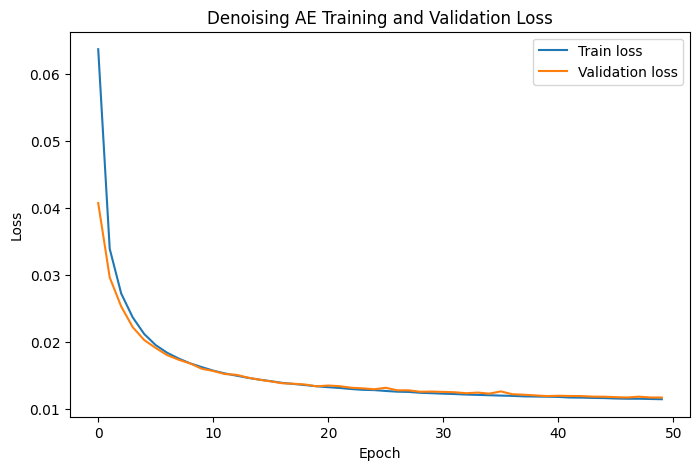

In [13]:
# =========================
# Plot Train / Validation Loss
# =========================
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Denoising AE Training and Validation Loss")
plt.legend()
plt.show()

Image 1: MSE = 0.00601
Image 2: MSE = 0.01038
Image 3: MSE = 0.00404
Image 4: MSE = 0.01309
Image 5: MSE = 0.01026


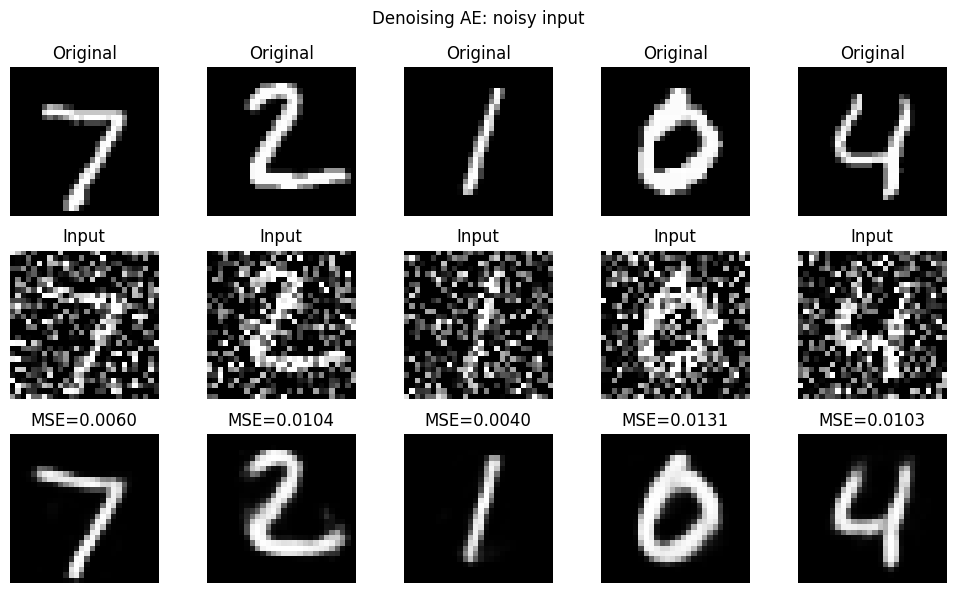


DAE, noisy input: mean MSE on all 10,000 test images = 0.01155
Error reduction vs. standard AE: 4.0x


In [14]:
dae_model = model

show_reconstructions(dae_model, x_test_noisy_all, x_test_all, title="Denoising AE: noisy input")

dae_noisy_mse = mse_full_test_set(dae_model, x_test_noisy_all, x_test_all)
print(f"\nDAE, noisy input: mean MSE on all 10,000 test images = {dae_noisy_mse:.5f}")
print(f"Error reduction vs. standard AE: {ae_noisy_mse / dae_noisy_mse:.1f}x")


# Variational Autoencoder (VAE)

In [15]:
# =========================
# Hyperparameters
# =========================
input_dim = 28 * 28
lat_space_dim = 50
batch_size = 256
n_epochs = 50
learning_rate = 0.001


In [16]:
# =========================
# VAE Model
# =========================
class MyVariationalAutoencoder(nn.Module):
    def __init__(self, input_dim, lat_space_dim):
        super().__init__()

        # Encoder
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 200),
            nn.ReLU(),
            nn.Linear(200, 100),
            nn.ReLU()
        )

        # q(z|x): mean and log-variance
        self.layer_latent_mean = nn.Linear(100, lat_space_dim)
        self.layer_latent_logvar = nn.Linear(100, lat_space_dim)

        # Decoder
        self.decoder = nn.Sequential(
            nn.Linear(lat_space_dim, 100),
            nn.ReLU(),
            nn.Linear(100, 200),
            nn.ReLU(),
            nn.Linear(200, input_dim),
            nn.Sigmoid()
        )

    ### z = μ + σϵ with ϵ ~ N(0, I)
    def reparameterize(self, mu, logvar):
        # logvar = log(sigma^2)
        std = torch.exp(0.5 * logvar)
        epsilon = torch.randn_like(std)
        z = mu + std * epsilon
        return z

    def forward(self, x):
        h = self.encoder(x)

        mu = self.layer_latent_mean(h)
        logvar = self.layer_latent_logvar(h)

        z = self.reparameterize(mu, logvar)

        x_hat = self.decoder(z)

        return x_hat, mu, logvar


model = MyVariationalAutoencoder(
    input_dim=input_dim,
    lat_space_dim=lat_space_dim
).to(device)

optimizer = optim.Adam(model.parameters(), lr=learning_rate)

In [17]:
# =========================
# VAE Loss Function
# =========================
def vae_loss(x_hat, x, mu, logvar):
    # Reconstruction loss
    reconstruction_loss = F.mse_loss(x_hat, x, reduction="sum")

    # KL divergence
    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return reconstruction_loss + kl_loss


In [18]:
# =========================
# Training Loop
# =========================
train_losses = []
val_losses = []

for epoch in range(1, n_epochs + 1):
    model.train()
    running_train_loss = 0.0

    for x_train, _ in train_loader:
        x_train = x_train.to(device)

        x_hat_train, mu, logvar = model(x_train)
        loss = vae_loss(x_hat_train, x_train, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    avg_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(avg_train_loss)

    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for x_val, _ in val_loader:
            x_val = x_val.to(device)

            x_hat_val, mu, logvar = model(x_val)
            val_loss = vae_loss(x_hat_val, x_val, mu, logvar)

            running_val_loss += val_loss.item()

    avg_val_loss = running_val_loss / len(val_loader.dataset)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch:02d}/{n_epochs} | "
        f"Train Loss: {avg_train_loss:.4f} | "
        f"Val Loss: {avg_val_loss:.4f}"
    )



Epoch 01/50 | Train Loss: 60.1330 | Val Loss: 50.2287
Epoch 02/50 | Train Loss: 48.9894 | Val Loss: 47.5316
Epoch 03/50 | Train Loss: 46.4955 | Val Loss: 44.7631
Epoch 04/50 | Train Loss: 42.9985 | Val Loss: 40.9765
Epoch 05/50 | Train Loss: 39.2267 | Val Loss: 37.7323
Epoch 06/50 | Train Loss: 36.8006 | Val Loss: 35.7330
Epoch 07/50 | Train Loss: 35.1962 | Val Loss: 34.7553
Epoch 08/50 | Train Loss: 34.1917 | Val Loss: 33.7868
Epoch 09/50 | Train Loss: 33.4984 | Val Loss: 33.3132
Epoch 10/50 | Train Loss: 33.0003 | Val Loss: 32.8337
Epoch 11/50 | Train Loss: 32.5750 | Val Loss: 32.5036
Epoch 12/50 | Train Loss: 32.2097 | Val Loss: 32.1310
Epoch 13/50 | Train Loss: 31.9173 | Val Loss: 31.9244
Epoch 14/50 | Train Loss: 31.6716 | Val Loss: 31.6632
Epoch 15/50 | Train Loss: 31.4342 | Val Loss: 31.4498
Epoch 16/50 | Train Loss: 31.2254 | Val Loss: 31.3071
Epoch 17/50 | Train Loss: 31.0447 | Val Loss: 31.1770
Epoch 18/50 | Train Loss: 30.8982 | Val Loss: 30.9847
Epoch 19/50 | Train Loss: 30

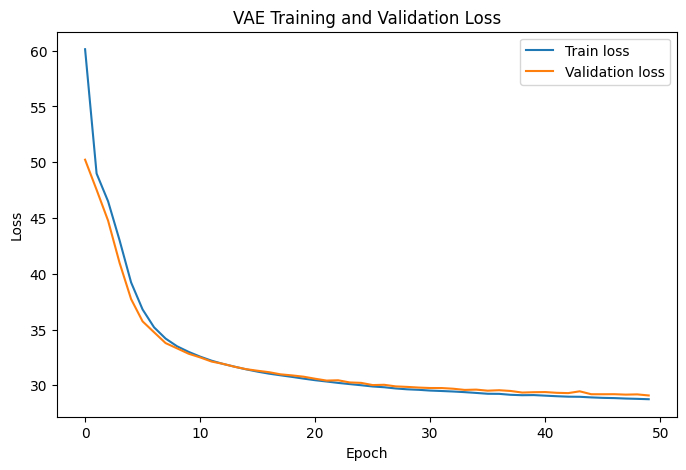

In [19]:
# =========================
# Plot Train / Validation Loss
# =========================
plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="Train loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training and Validation Loss")
plt.legend()
plt.show()

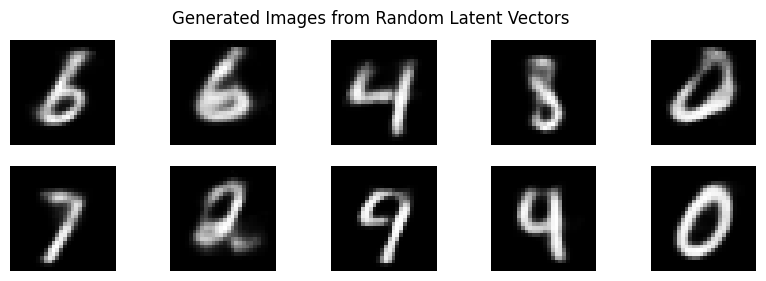

In [20]:
# =========================
# Generate New Images
# =========================
model.eval()

n = 10

# sample z from prior p(z) = N(0, I)
z_random = torch.randn(n, lat_space_dim).to(device)

with torch.no_grad():
    gen_images = model.decoder(z_random)

gen_images = gen_images.cpu().numpy()

plt.figure(figsize=(n, 3))

for i in range(n):
    ax = plt.subplot(2, n // 2, i + 1)
    plt.imshow(gen_images[i].reshape(28, 28), cmap="gray")
    plt.axis("off")

plt.suptitle("Generated Images from Random Latent Vectors")
plt.show()

In [21]:
print(f"{'Model':<14}{'Input':<8}{'Mean MSE':>10}")
print("-" * 32)
print(f"{'AE':<14}{'clean':<8}{ae_clean_mse:>10.5f}")
print(f"{'AE':<14}{'noisy':<8}{ae_noisy_mse:>10.5f}")
print(f"{'Denoising AE':<14}{'noisy':<8}{dae_noisy_mse:>10.5f}")
print(f"\nDenoising AE reduces the error on noisy images by {ae_noisy_mse / dae_noisy_mse:.1f}x")

Model         Input     Mean MSE
--------------------------------
AE            clean      0.00181
AE            noisy      0.04662
Denoising AE  noisy      0.01155

Denoising AE reduces the error on noisy images by 4.0x
